# App Insights Unlocked: Google Play Store Analysis
**Author's note:** I am learning data analytics and this is my project to practise EDA (exploratory data analysis) with Python. I went step by step: look at the data, clean it, then answer 25 questions (10 basic, 10 medium, 5 advanced).

**The big question:** what makes an app successful on the Google Play Store?

**Data (from Kaggle):**
* `googleplaystore.csv` - one row per app (rating, reviews, size, installs, price...)
* `googleplaystore_user_reviews.csv` - user review text with a sentiment label

**My plan**
1. Load and look at the data
2. Clean it
3. Basic questions
4. Medium questions
5. Advanced questions
6. Conclusions

## 1. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

apps = pd.read_csv("../data/raw/googleplaystore.csv")
reviews = pd.read_csv("../data/raw/googleplaystore_user_reviews.csv")

print("Apps file:", apps.shape)
print("Reviews file:", reviews.shape)

Apps file: (10841, 13)
Reviews file: (64295, 5)


In [2]:
apps.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
apps.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


## 2. Data cleaning
Everything in `apps` is text (object) except `Rating`, so I will need to convert several columns. First I check what is wrong with the data.

In [4]:
# How many missing values in each column?
apps.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [5]:
# Duplicates
print("Fully identical rows:", apps.duplicated().sum())
print("Repeated app names:", apps["App"].duplicated().sum())

Fully identical rows: 483
Repeated app names: 1181


Something looks odd: `Rating` should be at most 5, so let me look for strange values.

In [6]:
apps["Rating"].describe()

count    9367.000000
mean        4.193338
std         0.537431
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max        19.000000
Name: Rating, dtype: float64

In [7]:
# The max rating is 19, which is impossible. Which row is it?
apps[apps["Rating"] > 5]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


This row is broken: the values have shifted one column to the left (the Category says `1.9`). I can't be sure what the correct category is, so I will remove it.

In [8]:
apps = apps[apps["Rating"].isnull() | (apps["Rating"] <= 5)]
print("Rows left:", len(apps))

Rows left: 10840


### 2.1 Fix data types
`Reviews`, `Installs`, `Price` and `Size` should be numbers, and `Last Updated` should be a date.

In [9]:
apps["Reviews"] = apps["Reviews"].astype(int)

# Installs looks like "10,000+" -> remove "+" and "," then make it a number
apps["Installs"] = apps["Installs"].str.replace("+", "", regex=False)
apps["Installs"] = apps["Installs"].str.replace(",", "", regex=False)
apps["Installs"] = apps["Installs"].astype(int)

# Price looks like "$4.99"
apps["Price"] = apps["Price"].str.replace("$", "", regex=False)
apps["Price"] = apps["Price"].astype(float)

# Last Updated looks like "January 7, 2018"
apps["Last Updated"] = pd.to_datetime(apps["Last Updated"])

In [10]:
# Size looks like "19M" or "201k" or "Varies with device"
apps["Size"].value_counts().head()

Size
Varies with device    1695
11M                    198
12M                    196
14M                    194
13M                    191
Name: count, dtype: int64

In [11]:
# I'll turn size into megabytes. "Varies with device" can't be converted, so it becomes NaN.
apps["Size_MB"] = np.nan

is_mb = apps["Size"].str.endswith("M", na=False)
is_kb = apps["Size"].str.endswith("k", na=False)

apps.loc[is_mb, "Size_MB"] = apps.loc[is_mb, "Size"].str.replace("M", "").astype(float)
apps.loc[is_kb, "Size_MB"] = apps.loc[is_kb, "Size"].str.replace("k", "").astype(float) / 1024

apps[["Size", "Size_MB"]].head()

,Size,Size_MB
0,19M,19.0
1,14M,14.0
2,8.7M,8.7
3,25M,25.0
4,2.8M,2.8


### 2.2 Missing values
* `Type` has 1 missing value. That app has Price 0, so I fill it with `Free`.
* `Rating` has many missing values. I will **not** fill them in, because inventing ratings would make my results wrong. I will just ignore these apps for rating questions.

In [12]:
apps["Type"] = apps["Type"].fillna("Free")

### 2.3 Remove duplicates
Some apps appear more than once with different review counts. I keep the row with the most reviews.

In [13]:
before = len(apps)

apps = apps.drop_duplicates()
apps = apps.sort_values("Reviews", ascending=False)
apps = apps.drop_duplicates(subset="App", keep="first")

print("Rows before:", before)
print("Rows after :", len(apps))

Rows before: 10840
Rows after : 9659


### 2.4 Tidy text
Categories look like `ART_AND_DESIGN`. I make them nicer. Genres can have two parts (`Art & Design;Pretend Play`) so I keep only the first part as the main genre.

In [14]:
apps["Category"] = apps["Category"].str.replace("_", " ").str.title()
apps["Genre_Main"] = apps["Genres"].str.split(";").str[0]

apps[["Category", "Genres", "Genre_Main"]].head()

,Category,Genres,Genre_Main
2544,Social,Social,Social
336,Communication,Communication,Communication
2604,Social,Social,Social
382,Communication,Communication,Communication
1879,Game,Strategy,Strategy


In [15]:
# Dataset for rating questions (only apps that have a rating)
rated = apps.dropna(subset=["Rating"])

print("Total apps:", len(apps))
print("Apps with a rating:", len(rated))
apps.to_csv("../data/processed/googleplaystore_clean.csv", index=False)

Total apps: 9659
Apps with a rating: 8196


Cleaning done. Now the questions.

---
# 3. Basic questions

### Q1. What is the average rating of apps?

Average rating: 4.17
Median rating : 4.3


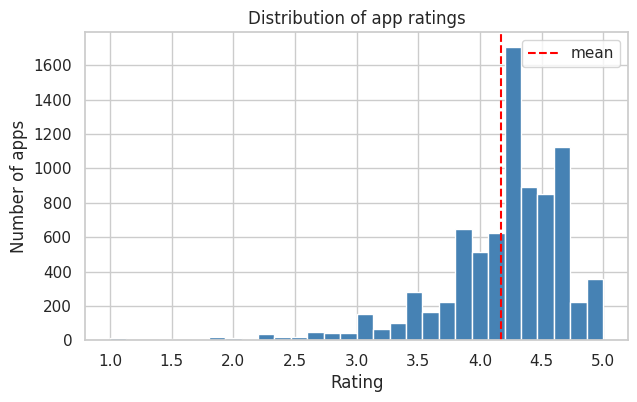

In [16]:
print("Average rating:", round(rated["Rating"].mean(), 2))
print("Median rating :", rated["Rating"].median())

plt.figure(figsize=(7, 4))
plt.hist(rated["Rating"], bins=30, color="steelblue")
plt.axvline(rated["Rating"].mean(), color="red", linestyle="--", label="mean")
plt.title("Distribution of app ratings")
plt.xlabel("Rating")
plt.ylabel("Number of apps")
plt.legend()
plt.show()

**What I see:** most apps are rated between 4 and 5, and there is a small tail of low ratings. That is why the median is higher than the mean.

### Q2. How many unique categories are there?

In [17]:
print("Unique categories:", apps["Category"].nunique())

category_counts = apps["Category"].value_counts()
category_counts.head(10)

Unique categories: 33


Category
Family             1876
Game                946
Tools               829
Business            420
Medical             395
Personalization     376
Productivity        374
Lifestyle           369
Finance             345
Sports              325
Name: count, dtype: int64

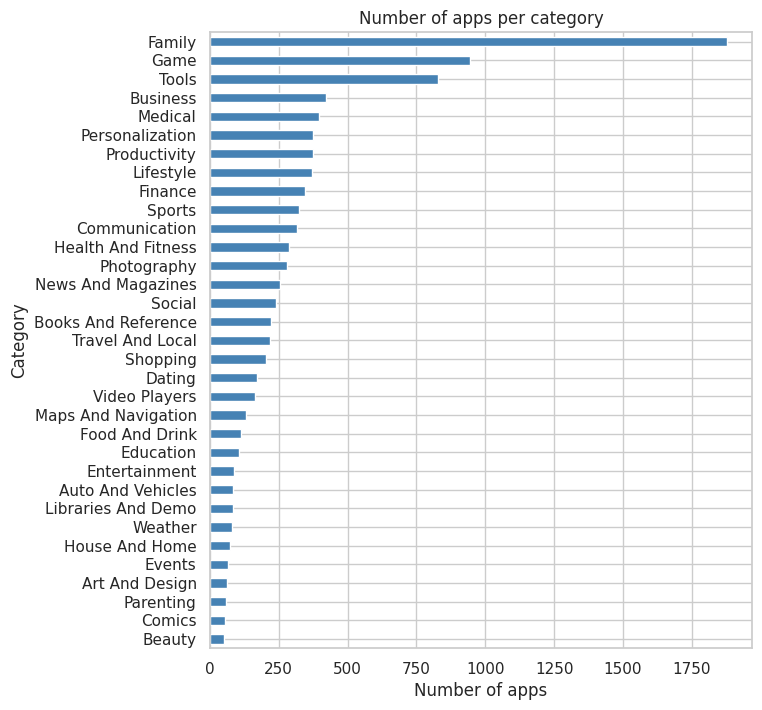

In [18]:
plt.figure(figsize=(7, 8))
category_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Number of apps per category")
plt.xlabel("Number of apps")
plt.show()

**What I see:** Family, Game and Tools have by far the most apps.

### Q3. What is the distribution of app sizes?

count    8431.000000
mean       20.398075
std        21.828959
min         0.008301
25%         4.600000
50%        12.000000
75%        28.000000
max       100.000000
Name: Size_MB, dtype: float64
Apps with unknown size: 1228


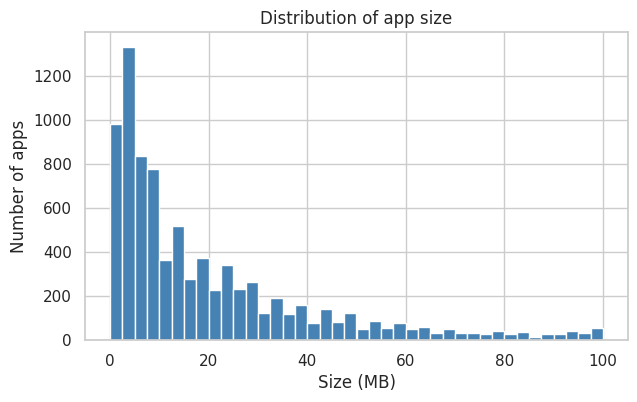

In [19]:
print(apps["Size_MB"].describe())
print("Apps with unknown size:", apps["Size_MB"].isnull().sum())

plt.figure(figsize=(7, 4))
plt.hist(apps["Size_MB"].dropna(), bins=40, color="steelblue")
plt.title("Distribution of app size")
plt.xlabel("Size (MB)")
plt.ylabel("Number of apps")
plt.show()

**What I see:** most apps are small, and a few big apps stretch the right side (right-skewed). The mean is bigger than the median because of those big apps.

### Q4. How many free vs paid apps?

Type
Free    8905
Paid     754
Name: count, dtype: int64

Type
Free    92.2
Paid     7.8
Name: count, dtype: float64


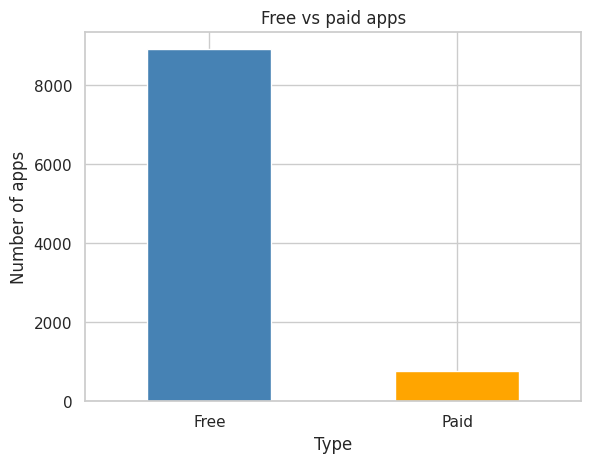

In [20]:
type_counts = apps["Type"].value_counts()
print(type_counts)
print()
print((type_counts / len(apps) * 100).round(1))

type_counts.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Free vs paid apps")
plt.ylabel("Number of apps")
plt.xticks(rotation=0)
plt.show()

### Q5. What is the most common content rating?

In [21]:
content_counts = apps["Content Rating"].value_counts()
print("Most common:", apps["Content Rating"].mode()[0])
print()
print(content_counts)

Most common: Everyone

Content Rating
Everyone           7903
Teen               1036
Mature 17+          393
Everyone 10+        322
Adults only 18+       3
Unrated               2
Name: count, dtype: int64


### Q6. What are the top 5 most installed apps?
`Installs` is a bucket (like "1,000,000,000+"), so many apps have exactly the same value. To break ties I sort by Reviews too.

In [22]:
top5 = apps.sort_values(["Installs", "Reviews"], ascending=False).head(5)
top5[["App", "Category", "Installs", "Reviews", "Rating"]]

,App,Category,Installs,Reviews,Rating
2544,Facebook,Social,1000000000,78158306,4.1
336,WhatsApp Messenger,Communication,1000000000,69119316,4.4
2604,Instagram,Social,1000000000,66577446,4.5
382,Messenger – Text and Video Chat for Free,Communication,1000000000,56646578,4.0
1872,Subway Surfers,Game,1000000000,27725352,4.5


In [23]:
print("Apps in the 1 billion bucket:", (apps["Installs"] == 1000000000).sum())

Apps in the 1 billion bucket: 20


**What I learned:** there is a big tie at the top, so "top 5" depends on how I break the tie.

### Q7. How many apps have a rating of 4.0 or above?

In [24]:
high = (rated["Rating"] >= 4.0).sum()
print("Apps rated 4.0+:", high)
print("As % of rated apps:", round(high / len(rated) * 100, 1), "%")

Apps rated 4.0+: 6287
As % of rated apps: 76.7 %


### Q8. Average number of reviews: free vs paid

In [25]:
reviews_by_type = apps.groupby("Type")["Reviews"].agg(["count", "mean", "median"])
reviews_by_type

,count,mean,median
Type,,,
Free,8905,234420.539248,1379.0
Paid,754,8748.010610,88.5


**What I see:** free apps get far more reviews. The mean is much bigger than the median, so a few huge apps pull the mean up. The median is a better "typical app" number.

### Q9. Average app size per category

In [26]:
size_by_category = apps.groupby("Category")["Size_MB"].mean().sort_values(ascending=False)
print(size_by_category.head(5))
print()
print(size_by_category.tail(5))

Category
Game                41.657327
Family              27.321612
Travel And Local    24.204375
Sports              24.058153
Entertainment       23.707143
Name: Size_MB, dtype: float64

Category
Art And Design        12.237288
Communication         11.306306
Personalization       11.223880
Libraries And Demo    10.598851
Tools                  8.770229
Name: Size_MB, dtype: float64


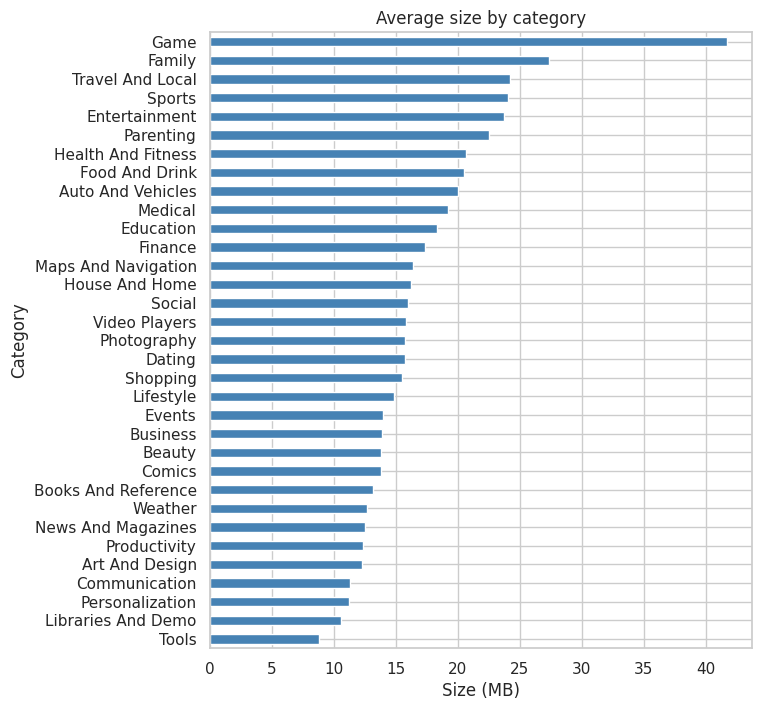

In [27]:
plt.figure(figsize=(7, 8))
size_by_category.sort_values().plot(kind="barh", color="steelblue")
plt.title("Average size by category")
plt.xlabel("Size (MB)")
plt.show()

### Q10. How many apps were last updated in 2018?

In [28]:
apps["Update_Year"] = apps["Last Updated"].dt.year
print(apps["Update_Year"].value_counts().sort_index())

n_2018 = (apps["Update_Year"] == 2018).sum()
print()
print("Updated in 2018:", n_2018, "(", round(n_2018 / len(apps) * 100, 1), "% )")

Update_Year
2010       1
2011      15
2012      26
2013     108
2014     203
2015     448
2016     779
2017    1792
2018    6287
Name: count, dtype: int64

Updated in 2018: 6287 ( 65.1 % )


---
# 4. Medium questions

### Q11. Correlation between installs and rating
Installs has huge values, so I try three ways: normal correlation, correlation with log of installs, and Spearman (compares ranks, so big values matter less).

Pearson (installs): 0.04
Pearson (log installs): 0.084
Spearman: 0.027


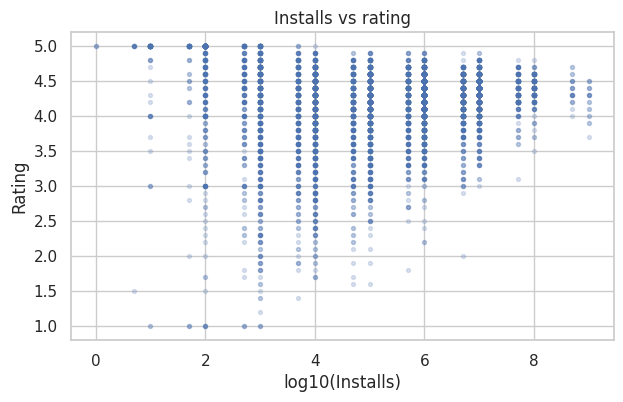

In [29]:
apps["Log_Installs"] = np.log10(apps["Installs"].replace(0, 1))   # replace 0 with 1 so log works
rated = apps.dropna(subset=["Rating"])

print("Pearson (installs):", round(rated["Installs"].corr(rated["Rating"]), 3))
print("Pearson (log installs):", round(rated["Log_Installs"].corr(rated["Rating"]), 3))
print("Spearman:", round(rated["Installs"].corr(rated["Rating"], method="spearman"), 3))

plt.figure(figsize=(7, 4))
plt.scatter(rated["Log_Installs"], rated["Rating"], alpha=0.2, s=8)
plt.title("Installs vs rating")
plt.xlabel("log10(Installs)")
plt.ylabel("Rating")
plt.show()

**What I see:** all the correlations are close to zero. More installs does not mean a better rating.

### Q12. Which categories have the highest average rating?

In [30]:
rating_by_category = rated.groupby("Category")["Rating"].agg(["count", "mean"])
rating_by_category = rating_by_category.sort_values("mean", ascending=False)
rating_by_category.head(5)

,count,mean
Category,,
Events,45,4.435556
Art And Design,59,4.359322
Education,105,4.351429
Books And Reference,169,4.344970
Personalization,298,4.332215


In [31]:
rating_by_category.tail(5)

,count,mean
Category,,
Travel And Local,187,4.069519
Video Players,149,4.044966
Tools,720,4.040278
Maps And Navigation,118,4.036441
Dating,133,3.980451


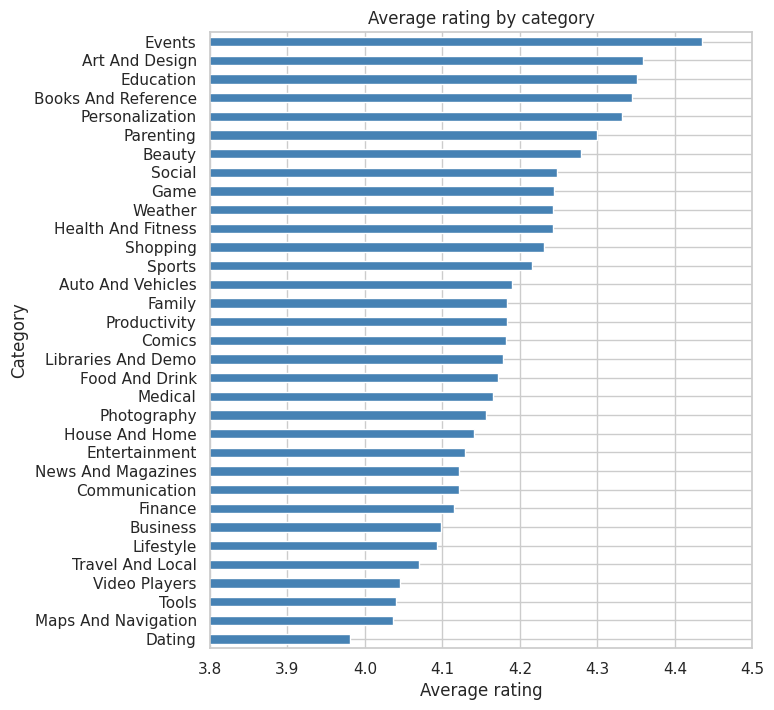

In [32]:
plt.figure(figsize=(7, 8))
rating_by_category["mean"].sort_values().plot(kind="barh", color="steelblue")
plt.xlim(3.8, 4.5)
plt.title("Average rating by category")
plt.xlabel("Average rating")
plt.show()

**Note to self:** a category with very few apps can have a high average just by luck, so I look at the `count` column too.

### Q13. How does price affect rating? (paid apps only)

In [33]:
paid = rated[rated["Type"] == "Paid"].copy()
print("Rated paid apps:", len(paid))
print("Correlation price vs rating:", round(paid["Price"].corr(paid["Rating"]), 3))

# group prices into bands so the result is easier to read
paid["Price_Band"] = pd.cut(paid["Price"], bins=[0, 1, 2, 5, 10, 1000], labels=["$0-1", "$1-2", "$2-5", "$5-10", "$10+"])
paid.groupby("Price_Band")["Rating"].agg(["count", "mean"])

Rated paid apps: 602
Correlation price vs rating: -0.114


,count,mean
Price_Band,,
$0-1,106,4.300943
$1-2,101,4.292079
$2-5,282,4.263830
$5-10,58,4.258621
$10+,55,4.127273


In [34]:
# Free vs paid average rating
rated.groupby("Type")["Rating"].mean()

Type
Free    4.166223
Paid    4.262126
Name: Rating, dtype: float64

**What I see:** the rating drops a little as price goes up, but paid apps as a group have a *higher* average than free apps. The $10+ group is odd because it includes a few joke apps that cost hundreds of dollars.

### Q14. Rating distribution across content ratings

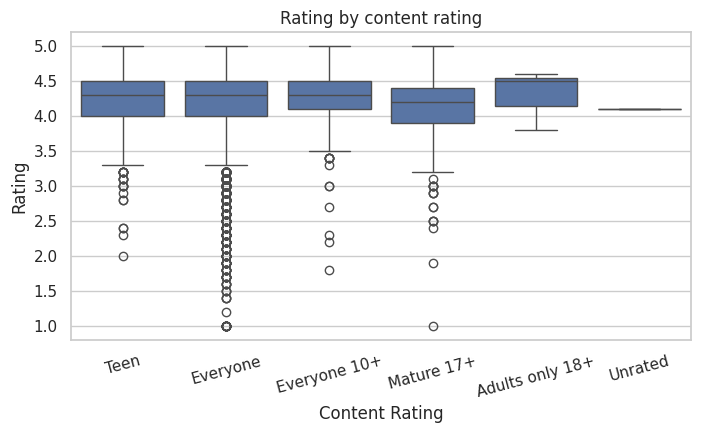

,count,mean,median
Content Rating,,,
Adults only 18+,3,4.300000,4.5
Everyone,6618,4.166349,4.3
Everyone 10+,305,4.225902,4.3
Mature 17+,357,4.121849,4.2
Teen,912,4.225658,4.3
Unrated,1,4.100000,4.1


In [35]:
plt.figure(figsize=(8, 4))
sns.boxplot(x="Content Rating", y="Rating", data=rated)
plt.title("Rating by content rating")
plt.xticks(rotation=15)
plt.show()

rated.groupby("Content Rating")["Rating"].agg(["count", "mean", "median"])

### Q15. Which genres have the most apps with over 1 million installs?

In [36]:
big_apps = apps[apps["Installs"] >= 1000000]

big_by_genre = big_apps["Genre_Main"].value_counts()
big_by_genre.head(10)

Genre_Main
Tools               275
Action              189
Entertainment       179
Photography         173
Productivity        147
Communication       140
Sports              125
Casual              122
Arcade              118
Health & Fitness    113
Name: count, dtype: int64

Tools has the most simply because it has a lot of apps. A fairer measure is the **share** of each genre's apps that reach 1M installs.

In [37]:
all_by_genre = apps["Genre_Main"].value_counts()
share = (big_by_genre / all_by_genre).dropna()

# only genres with at least 30 apps
share = share[all_by_genre >= 30]
(share.sort_values(ascending=False).head(5) * 100).round(0)

Genre_Main
Racing         69.0
Photography    62.0
Action         61.0
Strategy       61.0
Arcade         59.0
Name: count, dtype: float64

### Q16. How frequently do apps get updated?
**Problem:** each app has only ONE update date (its latest), so I cannot calculate the time *between* updates. Instead I measure how many days ago each app was last updated, counted from the newest date in the data.

In [38]:
latest_date = apps["Last Updated"].max()
apps["Days_Since_Update"] = (latest_date - apps["Last Updated"]).dt.days

print("Newest date in the data:", latest_date.date())
print(apps["Days_Since_Update"].describe())

Newest date in the data: 2018-08-08
count    9659.000000
mean      281.011388
std       406.721823
min         0.000000
25%        22.000000
50%        96.000000
75%       366.000000
max      3001.000000
Name: Days_Since_Update, dtype: float64


In [39]:
# Group apps by how recently they were updated
apps["Update_Group"] = pd.cut(apps["Days_Since_Update"], bins=[-1, 30, 90, 180, 365, 10000], labels=["0-30 days", "31-90 days", "91-180 days", "181-365 days", "Over 1 year"])

apps.groupby("Update_Group")[["Installs", "Rating"]].agg({"Installs": "median", "Rating": "mean"})

,Installs,Rating
Update_Group,,
0-30 days,1000000.0,4.270267
31-90 days,100000.0,4.208208
91-180 days,10000.0,4.146425
181-365 days,10000.0,4.116764
Over 1 year,10000.0,4.058167


**What I see:** apps updated recently have many more installs and slightly higher ratings. I can't say updating *causes* this (big apps may simply have more resources), but they go together.

### Q17. Impact of app size on installs

Spearman correlation: 0.31


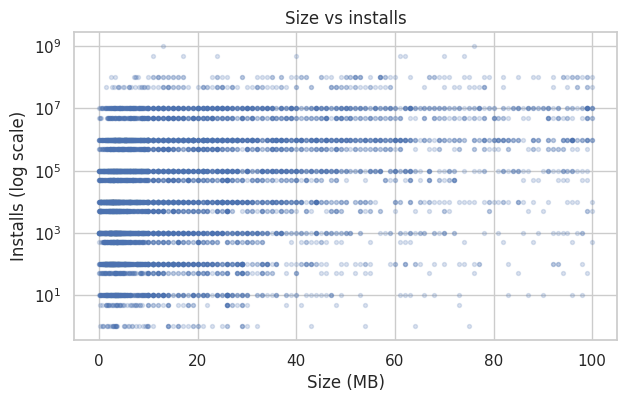

In [40]:
size_data = apps.dropna(subset=["Size_MB"])

print("Spearman correlation:", round(size_data["Size_MB"].corr(size_data["Installs"], method="spearman"), 3))

plt.figure(figsize=(7, 4))
plt.scatter(size_data["Size_MB"], size_data["Installs"], alpha=0.2, s=8)
plt.yscale("log")
plt.title("Size vs installs")
plt.xlabel("Size (MB)")
plt.ylabel("Installs (log scale)")
plt.show()

In [41]:
size_data = size_data.copy()
size_data["Size_Group"] = pd.cut(size_data["Size_MB"], bins=[0, 5, 10, 20, 50, 100], labels=["<5", "5-10", "10-20", "20-50", "50-100"])
size_data["Over_1M"] = size_data["Installs"] >= 1000000

(size_data.groupby("Size_Group")["Over_1M"].mean() * 100).round(1)

Size_Group
<5        13.8
5-10      24.1
10-20     30.1
20-50     38.5
50-100    58.9
Name: Over_1M, dtype: float64

**What I see:** bigger apps are more likely to reach 1M installs. I think size shows how much work went into the app (games and big company apps), so it is not a reason to make apps bigger.

### Q18. Apps with the most reviews and their ratings

In [42]:
apps.sort_values("Reviews", ascending=False).head(10)[["App", "Category", "Reviews", "Rating", "Type"]]

,App,Category,Reviews,Rating,Type
2544,Facebook,Social,78158306,4.1,Free
336,WhatsApp Messenger,Communication,69119316,4.4,Free
2604,Instagram,Social,66577446,4.5,Free
382,Messenger – Text and Video Chat for Free,Communication,56646578,4.0,Free
1879,Clash of Clans,Game,44893888,4.6,Free
4005,Clean Master- Space Cleaner & Antivirus,Tools,42916526,4.7,Free
1872,Subway Surfers,Game,27725352,4.5,Free
3665,YouTube,Video Players,25655305,4.3,Free
7536,"Security Master - Antivirus, VPN, AppLock, Boo...",Tools,24900999,4.7,Free
1878,Clash Royale,Game,23136735,4.6,Free


**What I see:** the most reviewed apps are social, messaging and game apps. They are all free and their ratings are between 4.0 and 4.7, so being huge does not mean being perfect.

### Q19. Content rating: free vs paid

In [43]:
counts = pd.crosstab(apps["Content Rating"], apps["Type"])
percent = (pd.crosstab(apps["Content Rating"], apps["Type"], normalize="columns") * 100).round(1)

print(counts)
print()
print(percent)

Type             Free  Paid
Content Rating             
Adults only 18+     3     0
Everyone         7250   653
Everyone 10+      291    31
Mature 17+        375    18
Teen              984    52
Unrated             2     0

Type             Free  Paid
Content Rating             
Adults only 18+   0.0   0.0
Everyone         81.4  86.6
Everyone 10+      3.3   4.1
Mature 17+        4.2   2.4
Teen             11.0   6.9
Unrated           0.0   0.0


### Q20. Top 5 categories by installs

Category
Game             13457924415
Communication    11038276251
Tools             8102771915
Family            6226542505
Productivity      5793091369
Name: Installs, dtype: int64

Share of all installs: 59.2 %


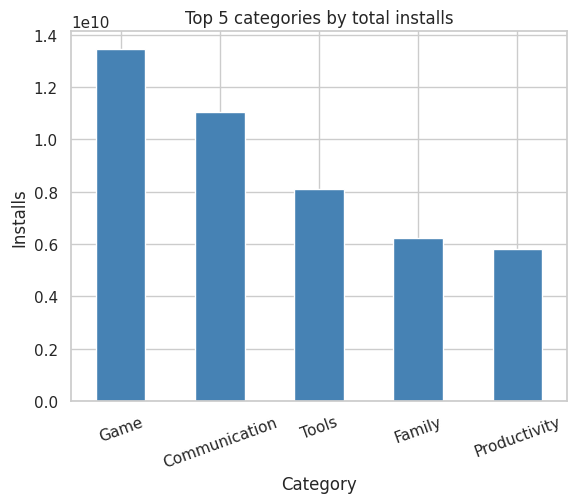

In [44]:
installs_by_category = apps.groupby("Category")["Installs"].sum().sort_values(ascending=False)
top5_categories = installs_by_category.head(5)
print(top5_categories)
print()
print("Share of all installs:", round(top5_categories.sum() / installs_by_category.sum() * 100, 1), "%")

top5_categories.plot(kind="bar", color="steelblue")
plt.title("Top 5 categories by total installs")
plt.ylabel("Installs")
plt.xticks(rotation=20)
plt.show()

**Note:** `Installs` is a lower bound (a "1M+" app might have 5M), so these totals are underestimates.

---
# 5. Advanced questions

### Q21. Top 10 highest-rated apps - how do their reviews and installs compare?
If I only sort by rating, I get apps with a perfect 5.0 and very few reviews. That is not fair, so I try two other ways.

In [45]:
# (a) simply sort by rating
simple_top10 = rated.sort_values(["Rating", "Reviews"], ascending=False).head(10)
simple_top10[["App", "Rating", "Reviews", "Installs"]]

,App,Rating,Reviews,Installs
10357,Ríos de Fe,5.0,141,1000
10301,"FD Calculator (EMI, SIP, RD & Loan Eligilibility)",5.0,104,1000
8058,Oración CX,5.0,103,5000
6823,Barisal University App-BU Face,5.0,100,1000
9496,Master E.K,5.0,90,1000
7506,CL REPL,5.0,47,1000
5230,AJ Cam,5.0,44,100
9517,Ek Vote,5.0,43,500
5196,AI Today : Artificial Intelligence News & AI 101,5.0,43,100
7842,CS & IT Interview Questions,5.0,43,1000


In [46]:
# (b) only apps with at least 1000 reviews
trusted = rated[rated["Reviews"] >= 1000]
trusted_top10 = trusted.sort_values(["Rating", "Reviews"], ascending=False).head(10)
trusted_top10[["App", "Category", "Rating", "Reviews", "Installs"]]

,App,Category,Rating,Reviews,Installs
9625,JW Library,Books And Reference,4.9,922752,10000000
1260,Six Pack in 30 Days - Abs Workout,Health And Fitness,4.9,272337,10000000
79,Tickets + PDA 2018 Exam,Auto And Vehicles,4.9,197136,1000000
712,"Learn Japanese, Korean, Chinese Offline & Free",Education,4.9,133136,1000000
1307,StrongLifts 5x5 Workout Gym Log & Personal Tra...,Health And Fitness,4.9,66791,1000000
7000,PixPanda - Color by Number Pixel Art Coloring ...,Family,4.9,55723,1000000
99,"ipsy: Makeup, Beauty, and Tips",Beauty,4.9,49790,1000000
3933,Hungry Hearts Diner: A Tale of Star-Crossed Souls,Family,4.9,46253,500000
1258,Lose Belly Fat in 30 Days - Flat Stomach,Health And Fitness,4.9,38098,5000000
4975,Solitaire: Decked Out Ad Free,Game,4.9,37302,500000


In [47]:
# (c) a weighted rating: apps with few reviews are pulled towards the overall average
overall_mean = rated["Rating"].mean()
m = 1000   # how many reviews I want before I trust the rating

rated = rated.copy()
rated["Weighted_Rating"] = (rated["Reviews"] / (rated["Reviews"] + m)) * rated["Rating"] + (m / (rated["Reviews"] + m)) * overall_mean

rated.sort_values("Weighted_Rating", ascending=False).head(10)[["App", "Rating", "Weighted_Rating", "Reviews"]]

,App,Rating,Weighted_Rating,Reviews
9625,JW Library,4.9,4.899213,922752
1260,Six Pack in 30 Days - Abs Workout,4.9,4.897341,272337
79,Tickets + PDA 2018 Exam,4.9,4.896332,197136
712,"Learn Japanese, Korean, Chinese Offline & Free",4.9,4.894582,133136
1307,StrongLifts 5x5 Workout Gym Log & Personal Tra...,4.9,4.889280,66791
7000,PixPanda - Color by Number Pixel Art Coloring ...,4.9,4.887188,55723
99,"ipsy: Makeup, Beauty, and Tips",4.9,4.885691,49790
3933,Hungry Hearts Diner: A Tale of Star-Crossed Souls,4.9,4.884620,46253
1258,Lose Belly Fat in 30 Days - Flat Stomach,4.9,4.881413,38098
4975,Solitaire: Decked Out Ad Free,4.9,4.881026,37302


In [48]:
five_star = rated[rated["Rating"] == 5.0]
print("Apps with a perfect 5.0:", len(five_star))
print("Their median reviews:", five_star["Reviews"].median())
print("Median reviews of all other apps:", rated[rated["Rating"] < 5.0]["Reviews"].median())

Apps with a perfect 5.0: 271
Their median reviews: 4.0
Median reviews of all other apps: 3656.0


**What I learned:** a perfect 5.0 usually means very few reviews. Once I require enough reviews, the best apps have 4.9 and hundreds of thousands of reviews, so quality and popularity can go together.

### Q22. Trend of app updates over time
Reminder: each app only has its latest update, so this shows how *fresh* the data is, not how often apps are released.

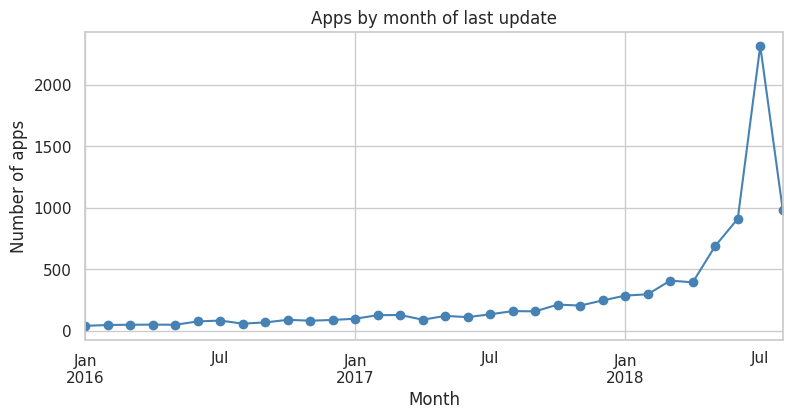

In [49]:
updates_per_month = apps["Last Updated"].dt.to_period("M").value_counts().sort_index()
updates_per_month = updates_per_month[updates_per_month.index >= "2016-01"]

plt.figure(figsize=(9, 4))
updates_per_month.plot(color="steelblue", marker="o")
plt.title("Apps by month of last update")
plt.xlabel("Month")
plt.ylabel("Number of apps")
plt.show()

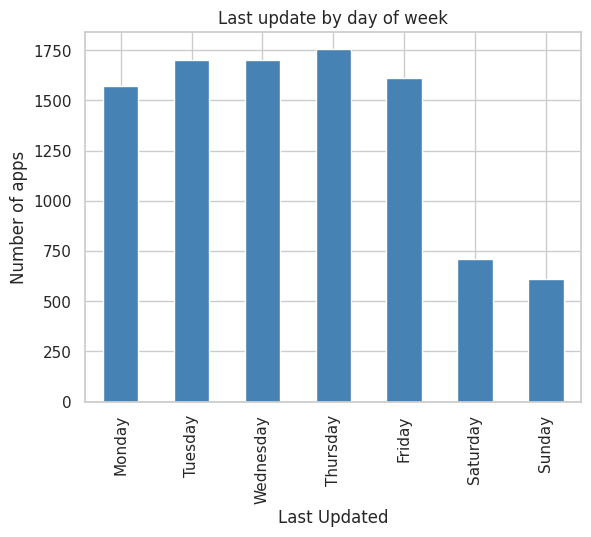

In [50]:
# Which day of the week?
weekday = apps["Last Updated"].dt.day_name().value_counts()
weekday = weekday.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])

weekday.plot(kind="bar", color="steelblue")
plt.title("Last update by day of week")
plt.ylabel("Number of apps")
plt.show()

**What I see:** the number rises steadily towards the end of the data (the recency effect), so I can't say anything about seasons from this data. The one clear pattern is that updates happen mostly on weekdays.

### Q23. How does rating change with installs? (binned analysis)

In [51]:
install_bins = [0, 1000, 10000, 100000, 1000000, 10000000, 100000000, 1000000000, 10000000000]
install_labels = ["<1K", "1K-10K", "10K-100K", "100K-1M", "1M-10M", "10M-100M", "100M-1B", "1B+"]

apps["Install_Group"] = pd.cut(apps["Installs"], bins=install_bins, labels=install_labels, right=False)

rating_by_installs = apps.groupby("Install_Group")["Rating"].agg(["count", "mean", "median", "std"])
rating_by_installs

,count,mean,median,std
Install_Group,,,,
<1K,638,4.345298,4.6,0.864638
1K-10K,1121,4.048617,4.2,0.734847
10K-100K,1443,4.038115,4.2,0.579530
100K-1M,1598,4.132416,4.2,0.466901
1M-10M,2022,4.220030,4.3,0.350132
10M-100M,1141,4.304557,4.3,0.277736
100M-1B,213,4.384977,4.4,0.187987
1B+,20,4.215000,4.3,0.225424


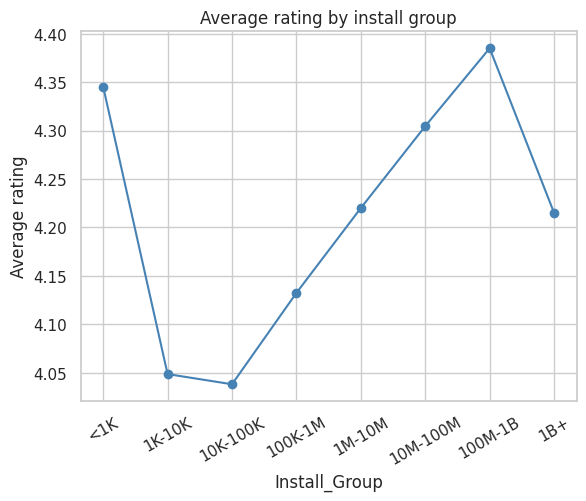

In [52]:
rating_by_installs["mean"].plot(marker="o", color="steelblue")
plt.title("Average rating by install group")
plt.ylabel("Average rating")
plt.xticks(rotation=30)
plt.show()

**What I see:** the line goes down then up (a "U" shape). Apps with very few installs have unreliable ratings (large std, and few apps are rated at all). As apps get bigger the ratings become more consistent (smaller std).

### Q24. Sentiment analysis of reviews
The reviews file already has a `Sentiment` column (Positive / Neutral / Negative) and `Sentiment_Polarity` (-1 to +1), so I don't have to build a sentiment model. My steps:
1. Remove reviews with no text, and join the app ratings
2. Compare sentiment for low-rated and high-rated apps
3. Find common themes and words

In [53]:
reviews_clean = reviews.dropna(subset=["Translated_Review", "Sentiment"])
reviews_clean = reviews_clean.merge(apps[["App", "Rating"]], on="App")
reviews_clean = reviews_clean.dropna(subset=["Rating"])

print("Reviews I can use:", len(reviews_clean))
print("Apps covered:", reviews_clean["App"].nunique())
print(reviews_clean["Sentiment"].value_counts())

Reviews I can use: 35929
Apps covered: 816
Sentiment
Positive    23073
Negative     8005
Neutral      4851
Name: count, dtype: int64


Sentiment       Negative  Neutral  Positive
App_Group                                  
Low (<4.0)          27.6     18.4      54.0
Mid (4.0-4.49)      22.1     15.2      62.7
High (>=4.5)        20.8      9.2      70.0


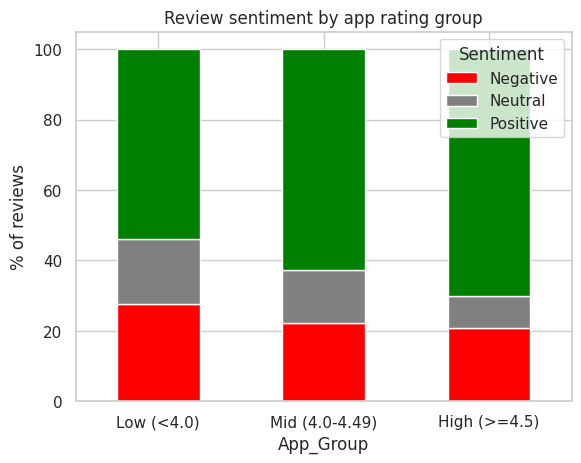

In [54]:
# Group apps by their rating
reviews_clean["App_Group"] = pd.cut(reviews_clean["Rating"], bins=[0, 3.999, 4.499, 5.0], labels=["Low (<4.0)", "Mid (4.0-4.49)", "High (>=4.5)"])

sentiment_by_group = pd.crosstab(reviews_clean["App_Group"], reviews_clean["Sentiment"], normalize="index") * 100
print(sentiment_by_group.round(1))

sentiment_by_group.plot(kind="bar", stacked=True, color=["red", "grey", "green"])
plt.title("Review sentiment by app rating group")
plt.ylabel("% of reviews")
plt.xticks(rotation=0)
plt.show()

In [55]:
# Do apps with a higher rating also have more positive reviews?
app_level = reviews_clean.groupby("App").agg(Rating=("Rating", "first"), Polarity=("Sentiment_Polarity", "mean"))
print("Correlation (app rating vs average polarity):", round(app_level["Rating"].corr(app_level["Polarity"], method="spearman"), 2))

Correlation (app rating vs average polarity): 0.24


**What I see:** higher-rated apps have more positive and fewer negative reviews, but the link is not perfect.

### Themes
To find themes, I choose some keywords for each topic and check how many reviews mention them. This is a simple method, so it is only a rough guide.

In [56]:
themes = {
    "Bugs, crashes & errors": r"crash|\bbugs?\b|freez|glitch|\blag|error|not work|doesn.?t work|\bfix",
    "Ads & interruptions": r"\bads?\b|advert|popup|pop-up",
    "Price & payments": r"price|expensive|\bpay|paid|money|subscription|premium|purchase",
    "Updates & versions": r"update|version",
    "Account / login / sync": r"login|log in|account|sign in|\bsync|password",
    "Ease of use & design": r"easy|simple|interface|design|user.?friendly|\bui\b|beautiful",
}

text = reviews_clean["Translated_Review"].str.lower()
theme_table = pd.DataFrame()

for theme_name, keywords in themes.items():
    mentions = text.str.contains(keywords)
    theme_table[theme_name] = mentions.groupby(reviews_clean["App_Group"]).mean() * 100

theme_table.T.round(1)

App_Group,Low (<4.0),Mid (4.0-4.49),High (>=4.5)
"Bugs, crashes & errors",18.0,12.6,10.6
Ads & interruptions,4.7,6.8,6.0
Price & payments,9.1,9.6,12.9
Updates & versions,12.7,10.1,8.9
Account / login / sync,7.1,4.2,3.7
Ease of use & design,8.7,8.1,11.9


Each number is the % of reviews in that group that mention the theme. I compare the Low and High columns.

In [57]:
# Most common words in negative vs positive reviews
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def top_words(sentiment, n=12):
    words = " ".join(reviews_clean.loc[reviews_clean["Sentiment"] == sentiment, "Translated_Review"].str.lower()).split()
    words = [w.strip(".,!?") for w in words]
    words = [w for w in words if len(w) > 3 and w not in ENGLISH_STOP_WORDS]
    return Counter(words).most_common(n)

print("Negative reviews:", top_words("Negative"))
print()
print("Positive reviews:", top_words("Positive"))

Negative reviews: [('game', 4206), ('time', 1387), ('like', 1239), ('play', 925), ("can't", 892), ('phone', 666), ('really', 663), ('update', 652), ("it's", 635), ('level', 538), ('money', 535), ('want', 533)]

Positive reviews: [('game', 4826), ('good', 4531), ('great', 4418), ('love', 4117), ('like', 3665), ('time', 2684), ('really', 2331), ('easy', 1964), ("it's", 1947), ('best', 1832), ('nice', 1514), ('better', 1465)]


**What I see:** low-rated apps have more reviews about bugs/crashes and login/account problems. Highly rated apps have more reviews about ease of use and design. (Word counts alone are not very clear because words like "game" and "app" are everywhere, so the theme table is more useful.)

**Limits:** the reviews file only covers a small part of the apps, and my keyword method is simple.

### Q25. Genre vs rating - are some genres consistently higher or lower?

In [58]:
genre_rating = rated.groupby("Genre_Main")["Rating"].agg(["count", "mean", "median", "std"])

# ignore genres with fewer than 20 rated apps
genre_rating = genre_rating[genre_rating["count"] >= 20].sort_values("mean", ascending=False)

print(genre_rating.head(5).round(2))
print()
print(genre_rating.tail(5).round(2))

                   count  mean  median   std
Genre_Main                                  
Events                45  4.44     4.5  0.42
Puzzle               123  4.37     4.4  0.34
Art & Design          62  4.35     4.4  0.36
Books & Reference    171  4.34     4.5  0.44
Personalization      298  4.33     4.4  0.36

                         count  mean  median   std
Genre_Main                                        
Video Players & Editors    150  4.04    4.20  0.56
Tools                      720  4.04    4.20  0.62
Trivia                      28  4.04    4.25  0.81
Maps & Navigation          118  4.04    4.20  0.53
Dating                     133  3.98    4.10  0.63


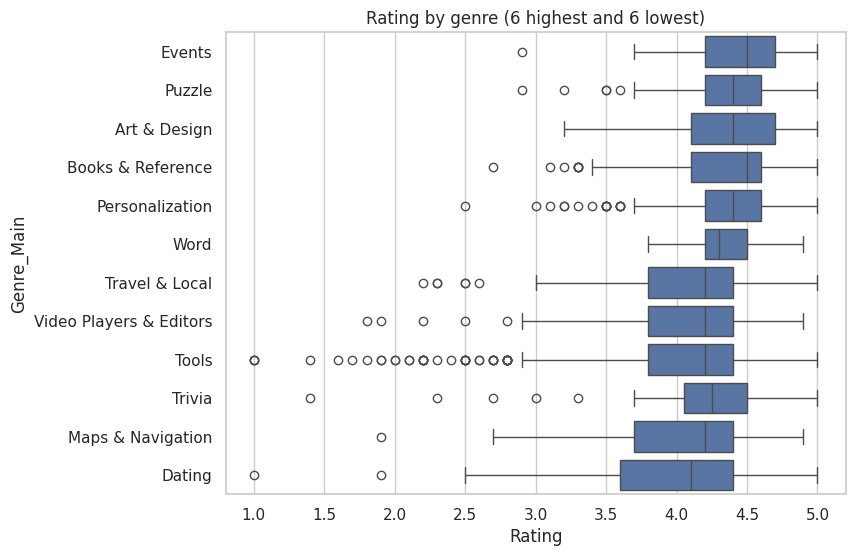

In [59]:
best_and_worst = list(genre_rating.head(6).index) + list(genre_rating.tail(6).index)

plt.figure(figsize=(8, 6))
sns.boxplot(y="Genre_Main", x="Rating", data=rated[rated["Genre_Main"].isin(best_and_worst)], order=best_and_worst)
plt.title("Rating by genre (6 highest and 6 lowest)")
plt.show()

**What I see:** yes, there are clear differences. Genres like Puzzle and Personalization are rated highly and their ratings are similar to each other (low std). Dating is the lowest and most spread out.

---
# 6. Conclusions
**What I found** (numbers are in the outputs above):
1. **Ratings are generally high.** Most apps are 4.0+, so 4.0 is the minimum, not a differentiator.
2. **Installs and rating are not related in a simple way.** The relationship is U-shaped, and ratings become more stable for big apps.
3. **Recently updated apps do better** (more installs, slightly higher ratings).
4. **Demand is concentrated** in a few categories (Game, Communication, Tools, Family, Productivity), and game genres and Photography are the best at reaching 1M installs.
5. **Users complain about reliability** (bugs, crashes, login) more in low-rated apps.
6. **Price:** paid apps are rated higher than free apps, but within paid apps ratings drop a little at higher prices.
7. **Genre matters:** puzzle/personalization/books tend to be rated high; dating, maps and tools lower.

**Suggestions for the company:** keep the app stable, fix login/sync issues, update regularly, think about category demand and not only rating, and judge apps by rating *and* number of reviews together.

**Limitations**
* The data is a single snapshot from 2018.
* Installs are ranges, not exact numbers.
* Each app has only one update date, so I couldn't measure the time between updates.
* The review data covers few apps and my theme method is simple.
* Everything here is correlation, not proof of cause.

**What I learned:** cleaning takes a lot of the time; a mean can be misleading when data is skewed (so check the median); and you should always check how many apps are behind an average.

*Data: Google Play Store Apps (Kaggle), CC BY 3.0.*